# Exploring Outbreak Dynamics

## Introduction

This notebook explores the dynamics of infectious disease transmission through a hypothetical outbreak of **Slurry-Throat Congestion (STC)**.

STC is an entirely fictional infectious condition characterized by the sensation of a thick, sticky, oatmeal-like substance coating the throat.

**STC is entirely fictional.** Its transmission characteristics, infectious period, recovery dynamics, and responses to public health interventions are hypothetical parameters selected for computational experimentation. No real pathogen, clinical syndrome, or observed outbreak is being modeled.

The simulations use the 2025 Vintage Estimates of the Resident Population for Counties and 2025 TIGER/Line Shapefiles. The original data sources are available from the [U.S. Census Bureau population estimates](https://www.census.gov/data/tables/time-series/demo/popest/2020s-counties-total.html) and [2025 TIGER/Line Shapefiles](https://www.census.gov/geographies/mapping-files/2025/geo/tiger-line-file.html).

Using these datasets, the simulations explore how epidemic dynamics change under different assumptions about transmission, population mixing, geographic connectivity, isolation, quarantine, and intervention timing.

The objective is not to forecast an actual outbreak, but to develop an intuitive and quantitative understanding of infectious disease modeling, progressing from classical susceptible–infectious–removed (SIR) models to geographically structured simulations.

## Data Loading and Setup

We use 2025 U.S. Census county population estimates and TIGER/Line geographic data to define the population and spatial structure of the simulations.

The processed datasets contain county-level population estimates, geographic identifiers, coordinates, and county adjacency relationships for the Contiguous United States (lower 48 states). These were constructed using `dataset_builder.py`.

All simulations use the same underlying population data, beginning with a single nationally aggregated population and progressing toward geographically structured models.

In [3]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.integrate import solve_ivp

# Load processed datasets

DATA_DIR = Path("Data_Processed")

counties = pd.read_csv(
    DATA_DIR / "counties.csv",
    dtype={"fips": str, "state_fips": str}
)

# DON'T NEED THIS YET

# edges = pd.read_csv(
#     DATA_DIR / "edges.csv",
#     dtype={"source_fips": str, "target_fips": str}
# )

geography = gpd.read_file(
    DATA_DIR / "county_network.geojson"
)

geography["fips"] = geography["fips"].astype(str).str.zfill(5)

# Validate datasets

assert counties["fips"].is_unique, "Duplicate county FIPS codes"
assert counties["population_2025"].notna().all(), "Missing populations"
assert (counties["population_2025"] > 0).all(), "Invalid populations"

# assert set(edges["source_fips"]).issubset(counties["fips"])
# assert set(edges["target_fips"]).issubset(counties["fips"])
assert set(geography["fips"]) == set(counties["fips"])

# Define total population

N = int(counties["population_2025"].sum())

print(f"Counties: {len(counties):,}")
# print(f"Border connections: {len(edges):,}")
print(f"Population (2025): {N:,}")

Counties: 3,108
Population (2025): 338,921,122


## 1. The Simplest Outbreak: Introducing the SIR Model

Before introducing geographic transmission or public health interventions, we begin with a classical **susceptible–infectious–removed (SIR)** model.

The SIR model divides a population into three compartments:

- **Susceptible ($S$)**: Individuals who have not been infected and remain susceptible to Disease STC.
- **Infectious ($I$)**: Individuals currently infected with STC who can transmit the disease.
- **Removed ($R$)**: Individuals who have recovered or otherwise left the infectious population and can no longer transmit STC.

Individuals transition from susceptible to infectious through transmission, and from infectious to removed through recovery or removal.

For this initial simulation, we make several simplifying assumptions:

1. The population is closed, with no births, deaths, or migration.

2. Individuals mix homogeneously, meaning that every individual has the same opportunity for infectious contact.

3. Transmission and removal rates remain constant throughout the outbreak.

4. Removed individuals cannot become susceptible again.

5. There is no incubation period, so newly infected individuals enter the infectious compartment immediately.

Although these assumptions are unrealistic for most infectious diseases, they provide a useful starting point for understanding how epidemics develop.

### 1.1 Mathematical Formulation

The classical SIR model describes how individuals move between three compartments over time: susceptible ($S$), infectious ($I$), and removed ($R$).

Rather than calculating the number of individuals in each compartment directly, the model first calculates **how quickly each compartment is changing**. These rates of change are described using ordinary differential equations.

#### Model parameters

We begin with the following hypothetical values for STC:

| Symbol | Description | Value |
|---|---|---|
| $N$ | Total population | Sum of 2025 county populations |
| $S_0$ | Initially susceptible | $N-100$ |
| $I_0$ | Initially infectious | 100 people |
| $R_{\mathrm{initial}}$ | Initially removed | 0 people |
| $\beta$ | Effective transmission-rate parameter | 0.30 per day |
| $\gamma$ | Per-capita removal rate | 0.10 per day |
| $t$ | Time | Days |

The population remains constant throughout the simulation:

$$
N=S+I+R
$$

The notation $dS/dt$, $dI/dt$, and $dR/dt$ represents the instantaneous rate of change in each compartment, measured in people per day. A positive value indicates an increasing population, while a negative value indicates a decreasing population. These equations calculate rates of change, not the exact number of people in each compartment on the following day.

#### Susceptible population

$$
\frac{dS}{dt}=-\beta\frac{SI}{N}
$$

The susceptible population decreases as individuals become infected.

The expression $\beta SI/N$ calculates the rate of new infections based on the current susceptible population, infectious population, and transmission parameter. The negative sign indicates that these infections remove individuals from the susceptible compartment.

#### Infectious population

$$
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I
$$

The infectious population changes through two competing processes:

1. **New infections** increase the infectious population.
2. **Removals** decrease the infectious population.

If new infections occur faster than removals, the infectious population grows. If removals occur faster than new infections, the infectious population declines.

#### Removed population

$$
\frac{dR}{dt}=\gamma I
$$

The removed population increases as infectious individuals recover or otherwise leave the infectious compartment.

With $\gamma=0.10$ per day, the model assumes that infectious individuals leave the compartment at a constant per-capita rate of 0.10 per day. Under this model, the average time spent infectious is:

$$
\frac{1}{\gamma}=\frac{1}{0.10}=10\text{ days}
$$

In [ ]:
I0 = 100
R0_initial = 0
S0 = N - I0 - R0_initial

# Hypothetical STC transmission parameters

beta = 0.30     # Effective transmission rate (per day)
gamma = 0.10    # Removal rate (per day)
days = 200      # Days to run simulation

# SIR differential equation definition

def sir_model(t, y, beta, gamma, N):
    # Susceptible, Infected, and Removed counts
    S, I, R = y

    # Instantaneous rate of new infections (people per day)
    new_infections = beta * S * I / N

    # Instantaneous rate of new removals (people per day)

    new_removals = gamma * I

    return [
        # People can only be removed from suceptible
        -new_infections,
        # New infections increase infected and new removals decrease infected
        new_infections - new_removals,
        # People can only be added to removed
        new_removals
    ]

# Solve the model

t = np.arange(days + 1)

solution = solve_ivp(
    sir_model,
    # Loop from 0--201 (200 days)
    t_span=(0, days),
    # Initial parameters for day 0
    y0=[S0, I0, R0_initial],
    # Transmission rate, removal rate, total population
    args=(beta, gamma, N),
    t_eval=t,
    rtol=1e-8,
    atol=1e-8
)

if not solution.success:
    raise RuntimeError(solution.message)

results = pd.DataFrame({
    "day": solution.t,
    "S": solution.y[0],
    "I": solution.y[1],
    "R": solution.y[2]
})

print(f"Peak infectious: {results['I'].max():,.0f}")
print(f"Peak day: {results.loc[results['I'].idxmax(), 'day']:.0f}")

Peak infectious: 101,832,729
Peak day: 79


### 1.2 Simulating the Outbreak

With the model equations defined, we can now simulate the spread of STC through the population.

We begin by introducing 100 infectious individuals into an otherwise susceptible population. Using hypothetical transmission and removal rates, we simulate changes in the three compartments over 200 days.

The model is implemented using Python's `solve_ivp()` function, which numerically solves the differential equations by evaluating how quickly each compartment changes over time.

The resulting estimates describe the number of susceptible, infectious, and removed individuals at each simulated day.

Peak infectious day: 79
Susceptible at peak: 33.42%
Theoretical threshold: 33.33%


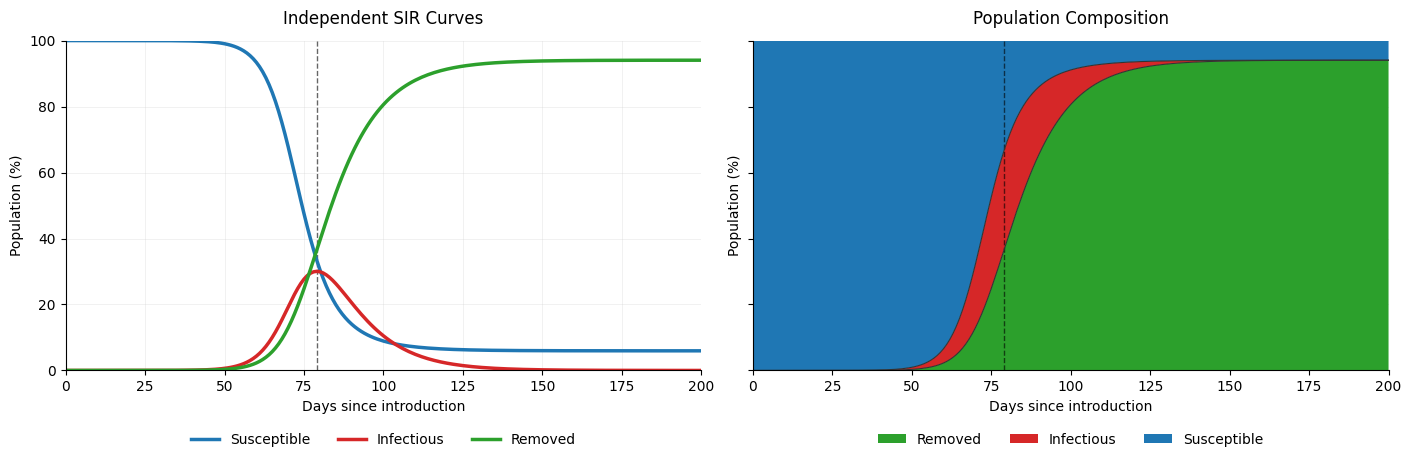

In [ ]:
from notebook_helpers import (
    sir_curves_plot,
    sir_stacked_plot,
)

# Plots

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax in axes:
    ax.axvline(
        peak_day,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.6,
    )

# Independent SIR curves

sir_curves_plot(
    results,
    N,
    ax=axes[0],
    title="Independent SIR Curves",
)

# Population composite SIR cur

sir_stacked_plot(
    results,
    N,
    ax=axes[1],
    title="Population Composition",
)

plt.show()